# **Escuela Nacional de Estudios Superiores, Unidad Morelia**
## **Final Project, Machine Learning**
### Adrián Lara A.

## **Models to use:**
#### - Decision Tree Classifier
#### - Logistic Regression Classifier
#### - Naive Bayes Classifier

The input is `data/processed/vgsales_clean.csv`, produced by `statistics/vgsales_stats.R` (cleaning + feature engineering).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from sklearn import metrics
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [2]:
DATA_PATH = Path("../data/processed/vgsales_clean.csv")
FIG_DIR = Path("../figures/machine_learning")
FIG_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
SALES_TIER_ORDER = ["Niche", "Moderate", "Hit", "Blockbuster"]

In [3]:
df = pd.read_csv(DATA_PATH)
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,...,Sales_Tier,Log_NA_Sales,Log_EU_Sales,Log_JP_Sales,Log_Other_Sales,Log_Global_Sales,NA_Share,EU_Share,JP_Share,Other_Share
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,...,Blockbuster,3.749269,3.401864,1.562346,2.247072,4.427717,0.501,0.351,0.046,0.102
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,...,Blockbuster,3.403860,1.521699,2.055405,0.570980,3.719409,0.723,0.089,0.169,0.019
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,...,Blockbuster,2.824351,2.630449,1.566530,1.460938,3.606041,0.442,0.360,0.106,0.092
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,...,Blockbuster,2.818398,2.485740,1.453953,1.376244,3.526361,0.477,0.334,0.099,0.090
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,...,Blockbuster,2.507157,2.291524,2.417698,0.693147,3.477232,0.359,0.283,0.326,0.032


In [4]:
model_columns = ["Decade", "Genre_Group", "Platform_Gen", "Publisher_Tier", "Sales_Tier"]
df[model_columns].isnull().sum()

Decade            0
Genre_Group       0
Platform_Gen      0
Publisher_Tier    0
Sales_Tier        0
dtype: int64

Missing values (58 unknown publishers, 271 missing years, and the 3 games on the 3DO platform) are already handled in the R preprocessing step, so every column used by the models is complete.

In [5]:
assert df[model_columns].notna().all().all()

In [6]:
# helpers shared by the three models

results = []

def evaluate(name, model, x_test, y_test, labels):
    y_pred = model.predict(x_test)
    scores = {
        "model": name,
        "accuracy": metrics.accuracy_score(y_test, y_pred),
        "balanced_accuracy": metrics.balanced_accuracy_score(y_test, y_pred),
        "macro_f1": metrics.f1_score(y_test, y_pred, average="macro", zero_division=0),
    }
    results.append(scores)
    print(pd.Series(scores).drop("model").round(4).to_string(), "\n")
    print(metrics.classification_report(y_test, y_pred, labels=labels, zero_division=0))
    return y_pred


def plot_confusion_matrix(y_test, y_pred, labels, title, filename, figsize=(8, 6), rotate=False):
    fig, ax = plt.subplots(figsize=figsize)
    metrics.ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, labels=labels, cmap="Blues", ax=ax
    )
    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    if rotate:
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(FIG_DIR / filename, dpi=150, bbox_inches="tight")
    plt.show()

# **Decision Tree**

### **Step 1: Selecting the features and target**
We have to select the features the model will use to predict the target. We exclude the original variables from the dataset because they are too dense, the derived variables hold most of the important information on them. It's also important to leave out all of the Sales variables from the features because `Sales_Tier` is built from `Global_Sales`: the model would just read the answer from them instead of learning patterns.

In [7]:
features = ["Decade", "Genre_Group", "Platform_Gen", "Publisher_Tier"]
target = "Sales_Tier"

x = df[features]
y = df[target]
print(x.shape, y.shape)

(16598, 4) (16598,)


In [8]:
y.value_counts().reindex(SALES_TIER_ORDER)

Sales_Tier
Niche          8392
Moderate       6152
Hit            1849
Blockbuster     205
Name: count, dtype: int64

Here we can see the target is very imbalanced (a consequence of the strongly right-skewed sales distribution), so we use the `stratify` parameter when splitting the data to keep the same class proportions in train and test.

The same split is reused by the Decision Tree and the Logistic Regression so both models are compared on exactly the same test set.

In [9]:
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)
print(x_train.shape, x_test.shape)

(13278, 4) (3320, 4)


### **Step 2: Encoding the variables**
Since the models can only work with numerical values, we encode our categorical features with `OrdinalEncoder` (one integer per category). The encoder lives inside a `Pipeline`, so it is fitted only on the training folds during cross-validation. scikit-learn classifiers accept the string labels of the target directly, so the target doesn't need encoding.

In [10]:
def tree_pipeline(**tree_params):
    return Pipeline(steps=[
        ("encoder", OrdinalEncoder()),
        ("tree", DecisionTreeClassifier(random_state=RANDOM_STATE, **tree_params)),
    ])

### **Step 3: Looking for the best parameters using GridSearchCV**

In [11]:
param_grid = {
    "tree__max_depth": list(range(1, 21)),
    "tree__min_samples_split": [5, 10],
    "tree__criterion": ["gini", "entropy"]
}

grid_search = GridSearchCV(
    estimator=tree_pipeline(),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
)
grid_search.fit(x_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", round(grid_search.best_score_, 4))

Best parameters: {'tree__criterion': 'gini', 'tree__max_depth': 9, 'tree__min_samples_split': 10}
Best CV accuracy: 0.5634


### **Step 4: Training the Model**
`GridSearchCV` refits the best configuration on the whole training set, so `best_estimator_` is already the trained model.

In [12]:
tree_model = grid_search.best_estimator_

### **Step 5: Evaluation and scoring**

In [13]:
y_pred = evaluate("Decision Tree", tree_model, x_test, y_test, SALES_TIER_ORDER)

accuracy             0.5645
balanced_accuracy    0.3309
macro_f1             0.3248 

              precision    recall  f1-score   support

       Niche       0.65      0.68      0.67      1679
    Moderate       0.47      0.58      0.52      1230
         Hit       0.35      0.07      0.11       370
 Blockbuster       0.00      0.00      0.00        41

    accuracy                           0.56      3320
   macro avg       0.37      0.33      0.32      3320
weighted avg       0.54      0.56      0.54      3320



These results may seem pretty low, but it's actually normal considering the nature of this dataset. Accuracy is dominated by the two big classes, and the model never predicts the rarest one (Blockbuster). One thing we can do to improve predictions on the less dominant classes is add the `class_weight` parameter when training the model, at the cost of Niche accuracy (the dominant class).

### **Branch: Training with `class_weight="balanced"`**
`class_weight="balanced"` weights every sample inversely to its class frequency. If we tuned this model with `scoring="accuracy"` the search would simply prefer the unweighted tree (accuracy rewards predicting the majority class), so the balanced tree is tuned with **balanced accuracy** (the mean recall over the four classes) instead.

In [14]:
grid_search_balanced = GridSearchCV(
    estimator=tree_pipeline(class_weight="balanced"),
    param_grid=param_grid,
    cv=5,
    scoring="balanced_accuracy"
)
grid_search_balanced.fit(x_train, y_train)

best_depth = grid_search_balanced.best_params_["tree__max_depth"]
print("Best parameters:", grid_search_balanced.best_params_)
print("Best CV balanced accuracy:", round(grid_search_balanced.best_score_, 4))

Best parameters: {'tree__criterion': 'gini', 'tree__max_depth': 11, 'tree__min_samples_split': 10}
Best CV balanced accuracy: 0.4033


In [15]:
balanced_tree_model = grid_search_balanced.best_estimator_
y_pred = evaluate("Decision Tree (balanced)", balanced_tree_model, x_test, y_test, SALES_TIER_ORDER)

accuracy             0.3955
balanced_accuracy     0.406
macro_f1             0.3004 

              precision    recall  f1-score   support

       Niche       0.73      0.52      0.61      1679
    Moderate       0.47      0.24      0.32      1230
         Hit       0.17      0.33      0.22       370
 Blockbuster       0.03      0.54      0.05        41

    accuracy                           0.40      3320
   macro avg       0.35      0.41      0.30      3320
weighted avg       0.56      0.40      0.45      3320



Overall accuracy drops, but recall on Hit and Blockbuster improves a lot: the balanced tree trades accuracy on the majority class for the ability to detect the rare ones. Once again, these results are to be expected given the nature of the data.

### **Feature importance**

In [16]:
pd.DataFrame({
    "unweighted": tree_model.named_steps["tree"].feature_importances_,
    "balanced": balanced_tree_model.named_steps["tree"].feature_importances_,
}, index=features).sort_values("balanced", ascending=False).round(3)

,unweighted,balanced
Genre_Group,0.218,0.292
Publisher_Tier,0.411,0.290
Platform_Gen,0.281,0.252
Decade,0.090,0.165


### **Additional Step: Plotting this tree**

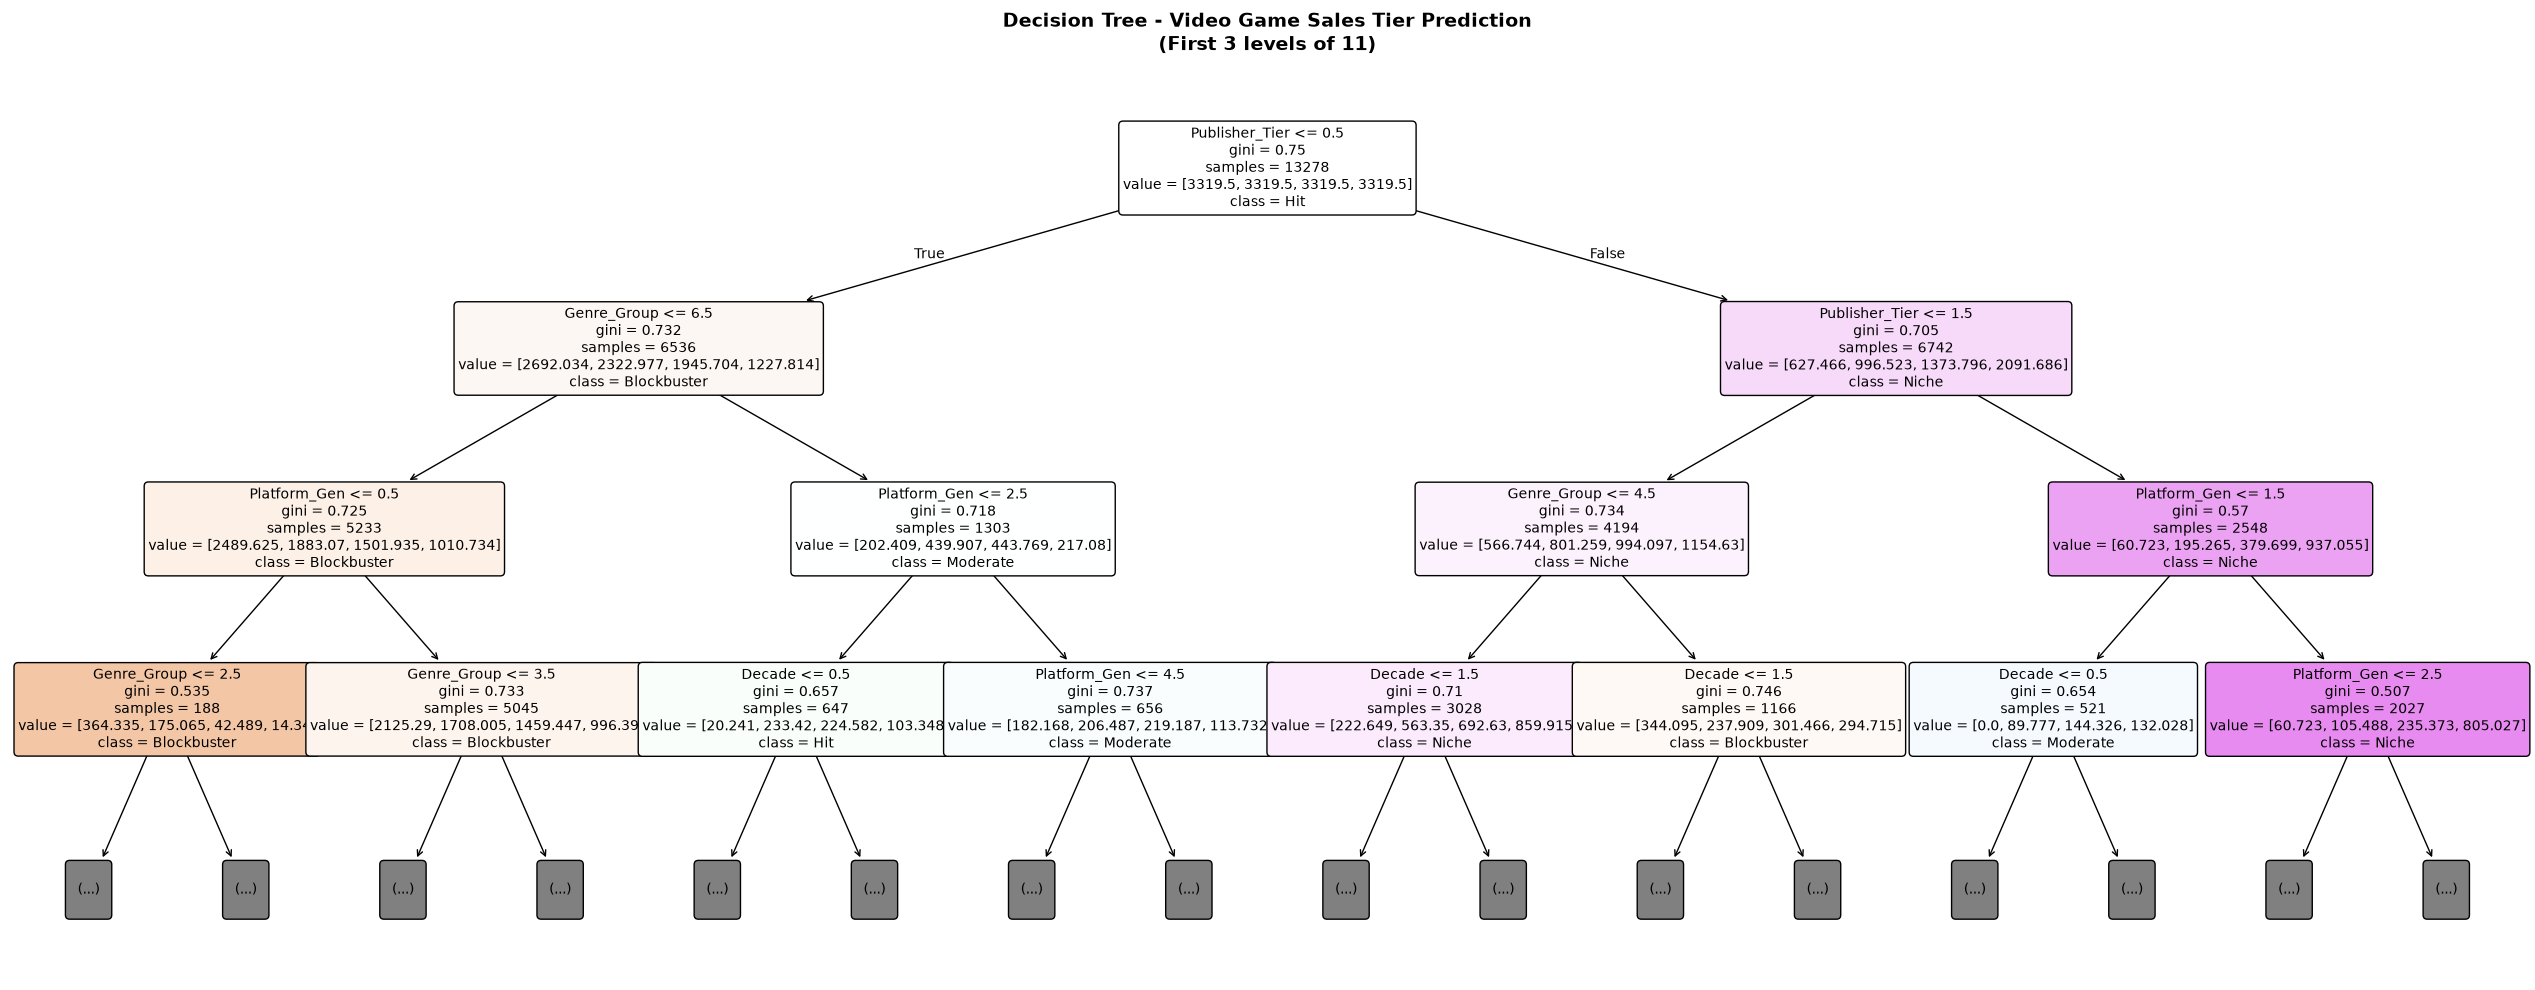

In [17]:
tree = balanced_tree_model.named_steps["tree"]

fig, ax = plt.subplots(figsize=(26, 10))
plot_tree(
    tree,
    max_depth=3,
    feature_names=features,
    class_names=list(tree.classes_),
    filled=True,
    rounded=True,
    fontsize=10,
    ax=ax
)
plt.title(f"Decision Tree - Video Game Sales Tier Prediction\n(First 3 levels of {best_depth})",
          fontsize=14, fontweight="bold", pad=20)
plt.tight_layout()
plt.savefig(FIG_DIR / "decision_tree_plot.png", dpi=150, bbox_inches="tight")
plt.show()

# **Logistic Regression**

### **Step 1: Choosing the features and target**
For this model we'll use the same prediction features, target and train/test split as the Decision Tree Classifier.

### **Step 2: Preprocessing and Pipeline**
Logistic regression treats inputs as numbers, so ordinal codes would impose a fake order on the categories. Instead we one-hot encode the features. With more than two classes, scikit-learn fits a multinomial (softmax) logistic regression by default. `class_weight="balanced"` is used for the same reason as in the balanced tree.

In [18]:
preprocessor = ColumnTransformer(transformers=[
    ("onehot", OneHotEncoder(handle_unknown="ignore"), features)
])

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("scaler", StandardScaler(with_mean=False)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

### **Step 3: Finding hyperparameter C**
`C` is the inverse of the regularization strength. As with the balanced tree, we tune it with balanced accuracy.

In [19]:
param_grid = {
    "classifier__C": [0.001, 0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="balanced_accuracy"
)
grid_search.fit(x_train, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best CV balanced accuracy:", round(grid_search.best_score_, 4))

Best parameters: {'classifier__C': 0.01}
Best CV balanced accuracy: 0.3995


### **Step 4: Predictions and evaluation of the model**

In [20]:
lr_model = grid_search.best_estimator_
y_pred = evaluate("Logistic Regression (balanced)", lr_model, x_test, y_test, SALES_TIER_ORDER)

accuracy             0.3991
balanced_accuracy    0.4114
macro_f1             0.2874 

              precision    recall  f1-score   support

       Niche       0.69      0.57      0.62      1679
    Moderate       0.46      0.23      0.31      1230
         Hit       0.16      0.16      0.16       370
 Blockbuster       0.03      0.68      0.06        41

    accuracy                           0.40      3320
   macro avg       0.34      0.41      0.29      3320
weighted avg       0.54      0.40      0.45      3320



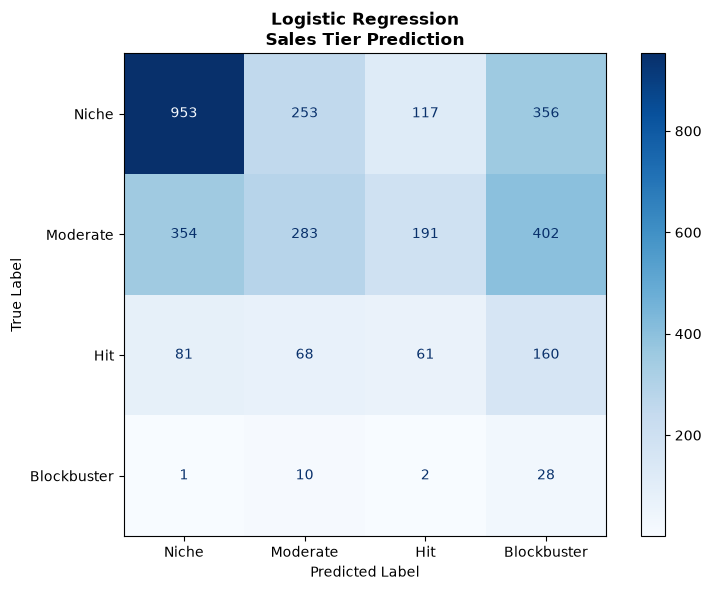

In [21]:
plot_confusion_matrix(
    y_test, y_pred, SALES_TIER_ORDER,
    title="Logistic Regression\nSales Tier Prediction",
    filename="lr_confusion_matrix.png"
)

# **Naive Bayes**

### **Step 1: Select the features and target**
In this case, we'll use a different target: we try to predict the game's `Genre_Group` from its decade, sales tier, platform generation and publisher tier. All features are categorical, so we use `CategoricalNB`, which models each feature with a categorical distribution per class.

Naive Bayes assumes the features are **conditionally independent given the class**. Here that assumption is clearly violated: for example, `Decade` and `Platform_Gen` are strongly related (each console generation belongs to a specific time period), which is one of the reasons we expect weak results.

In [22]:
nb_features = ["Decade", "Sales_Tier", "Platform_Gen", "Publisher_Tier"]
nb_target = "Genre_Group"
genre_order = sorted(df[nb_target].unique())

x_nb = df[nb_features]
y_nb = df[nb_target]

### **Step 2: Splitting the data**

In [23]:
x_train_nb, x_test_nb, y_train_nb, y_test_nb = train_test_split(
    x_nb, y_nb,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_nb
)

### **Step 3: Encoding and finding the hyperparameter alpha**
`CategoricalNB` expects each feature encoded as integers `0..n_categories-1`, so we use `OrdinalEncoder` inside a pipeline. `alpha` controls the "strength" of Laplace smoothing during the calculations.

In [24]:
nb_pipeline = Pipeline(steps=[
    ("encoder", OrdinalEncoder()),
    ("nb", CategoricalNB())
])

param_grid = {
    "nb__alpha": [0.01, 0.1, 0.5, 1.0, 2.0, 5.0, 10.0]
}

grid_search = GridSearchCV(
    estimator=nb_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
)
grid_search.fit(x_train_nb, y_train_nb)

print("Best parameters:", grid_search.best_params_)
print("Best CV accuracy:", round(grid_search.best_score_, 4))

Best parameters: {'nb__alpha': 5.0}
Best CV accuracy: 0.2726


### **Step 4: Predictions and evaluation of the model**

In [25]:
nb_model = grid_search.best_estimator_
y_pred = evaluate("Naive Bayes (genre)", nb_model, x_test_nb, y_test_nb, genre_order)

accuracy             0.2756
balanced_accuracy    0.1809
macro_f1             0.1455 

              precision    recall  f1-score   support

      Action       0.29      0.41      0.34       663
   Adventure       0.25      0.14      0.18       257
        Misc       0.00      0.00      0.00       348
       Other       0.29      0.61      0.39       773
      Racing       0.00      0.00      0.00       250
Role-Playing       0.00      0.00      0.00       298
     Shooter       0.00      0.00      0.00       262
      Sports       0.23      0.28      0.25       469

    accuracy                           0.28      3320
   macro avg       0.13      0.18      0.15      3320
weighted avg       0.18      0.28      0.21      3320



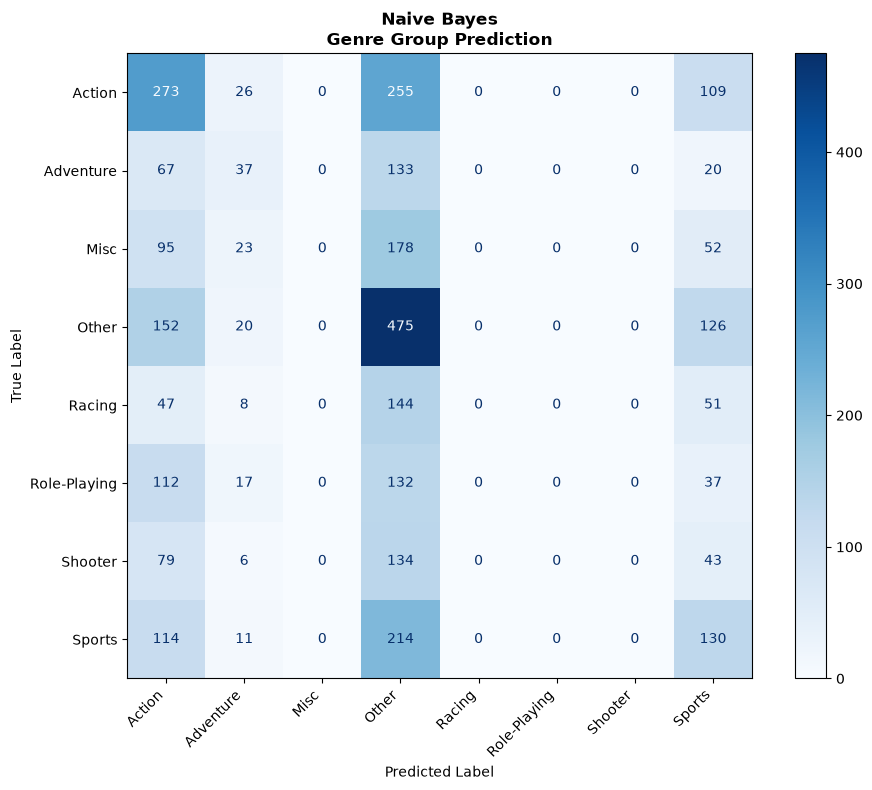

In [26]:
plot_confusion_matrix(
    y_test_nb, y_pred, genre_order,
    title="Naive Bayes\nGenre Group Prediction",
    filename="nb_confusion_matrix.png",
    figsize=(10, 8),
    rotate=True
)

These results may seem very bad, but it's actually kind of logical. Given the features, the model did its best at predicting the genres, but these features alone are very weak predictors of a video game's genre, and their dependence on each other breaks the Naive Bayes assumption. The model ends up predicting mostly the largest classes (Other, Action, Sports), and four of the eight genres (Misc, Racing, Role-Playing, Shooter) are never predicted at all.

# **Summary**
Note that the Naive Bayes model predicts a different target (8 genre classes) than the other models (4 sales tiers), so its scores are not directly comparable.

In [27]:
pd.DataFrame(results).set_index("model").round(4)

,accuracy,balanced_accuracy,macro_f1
model,,,
Decision Tree,0.5645,0.3309,0.3248
Decision Tree (balanced),0.3955,0.4060,0.3004
Logistic Regression (balanced),0.3991,0.4114,0.2874
Naive Bayes (genre),0.2756,0.1809,0.1455
